In [19]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import requests
import os

# Simple relative path — works on any machine
base = "data"

files = {
    "cpu_util_1" : r'c:\Anomaly detection\data\ec2_cpu_utilization_24ae8d.csv',
    "cpu_util_2" : r'c:\Anomaly detection\data\ec2_cpu_utilization_fe7f93.csv',
    "rds_cpu"    : r'c:\Anomaly detection\data\rds_cpu_utilization_cc0c53.csv',
}

raw = {}
for name, fname in files.items():
    filepath = os.path.join(base, fname)
    df = pd.read_csv(filepath)
    
    # Fix: force timestamp parsing explicitly
    df["timestamp"] = pd.to_datetime(df["timestamp"])
    df = df.set_index("timestamp")
    df = df.rename(columns={"value": name})
    
    raw[name] = df
    print(f"{name:15s} → {len(df):>5} rows")
    print(f"  columns : {list(df.columns)}")
    print(f"  sample  : \n{df.head(3)}\n")

cpu_util_1      →  4032 rows
  columns : ['cpu_util_1']
  sample  : 
                     cpu_util_1
timestamp                      
2014-02-14 14:30:00       0.132
2014-02-14 14:35:00       0.134
2014-02-14 14:40:00       0.134

cpu_util_2      →  4032 rows
  columns : ['cpu_util_2']
  sample  : 
                     cpu_util_2
timestamp                      
2014-02-14 14:27:00       2.296
2014-02-14 14:32:00       2.144
2014-02-14 14:37:00       2.274

rds_cpu         →  4032 rows
  columns : ['rds_cpu']
  sample  : 
                     rds_cpu
timestamp                   
2014-02-14 14:30:00    6.456
2014-02-14 14:35:00    5.816
2014-02-14 14:40:00    6.268



 Load anomaly labels

In [20]:
labels_url = (
    "https://raw.githubusercontent.com/numenta/NAB/"
    "master/labels/combined_windows.json"
)
label_windows = requests.get(labels_url).json()
print(f"Labels loaded — {len(label_windows)} entries")

nab_keys = {
    "cpu_util_1" : "realAWSCloudwatch/ec2_cpu_utilization_24ae8d.csv",
    "cpu_util_2" : "realAWSCloudwatch/ec2_cpu_utilization_fe7f93.csv",
    "rds_cpu"    : "realAWSCloudwatch/rds_cpu_utilization_cc0c53.csv",
}

def windows_to_flags(index, windows):
    flags = pd.Series(0, index=index, name="is_anomaly")
    for start_str, end_str in windows:
        start = pd.to_datetime(start_str)
        end   = pd.to_datetime(end_str)
        flags.loc[start:end] = 1
    return flags

for name, df in raw.items():
    windows = label_windows.get(nab_keys[name], [])
    df["is_anomaly"] = windows_to_flags(df.index, windows)
    n = df["is_anomaly"].sum()
    print(f"{name:15s} → {n:>3} anomaly rows ({n/len(df)*100:.1f}%)")

Labels loaded — 58 entries
cpu_util_1      → 402 anomaly rows (10.0%)
cpu_util_2      → 405 anomaly rows (10.0%)
rds_cpu         → 402 anomaly rows (10.0%)


 Merge the 3 overlapping series only

In [21]:
# Resample each series to 5-min intervals (mean) to align timestamps
overlapping = ["cpu_util_1", "cpu_util_2", "rds_cpu"]

resampled = {}
for name in overlapping:
    df_r = raw[name].resample("5min").mean()
    df_r[f"is_anomaly_{name}"] = raw[name]["is_anomaly"].resample("5min").max()
    resampled[name] = df_r
    print(f"{name:15s} → {len(df_r)} rows after resample | "
          f"first: {df_r.index[0]} | last: {df_r.index[-1]}")

# Now merge — timestamps are aligned
df_values = pd.concat(
    [resampled[n][n] for n in overlapping],
    axis=1, join="inner"
)
df_flags = pd.concat(
    [resampled[n][f"is_anomaly_{n}"] for n in overlapping],
    axis=1, join="inner"
)

df = pd.concat([df_values, df_flags], axis=1)
df["is_anomaly"] = df[[c for c in df.columns
                        if c.startswith("is_anomaly_")]].max(axis=1)

# Drop any NaN rows from resampling edges
df = df.dropna()

print(f"\nShape        : {df.shape}")
print(f"Time range   : {df.index.min()} → {df.index.max()}")
print(f"Anomaly rows : {int(df['is_anomaly'].sum())} "
      f"({df['is_anomaly'].mean()*100:.2f}%)")
print(f"\nFirst 3 rows:\n{df.head(3)}")

cpu_util_1      → 4032 rows after resample | first: 2014-02-14 14:30:00 | last: 2014-02-28 14:25:00
cpu_util_2      → 4032 rows after resample | first: 2014-02-14 14:25:00 | last: 2014-02-28 14:20:00
rds_cpu         → 4033 rows after resample | first: 2014-02-14 14:30:00 | last: 2014-02-28 14:30:00

Shape        : (4030, 7)
Time range   : 2014-02-14 14:30:00 → 2014-02-28 14:20:00
Anomaly rows : 1037 (25.73%)

First 3 rows:
                     cpu_util_1  cpu_util_2  rds_cpu  is_anomaly_cpu_util_1  \
timestamp                                                                     
2014-02-14 14:30:00       0.132       2.144    6.456                      0   
2014-02-14 14:35:00       0.134       2.274    5.816                      0   
2014-02-14 14:40:00       0.134       2.066    6.268                      0   

                     is_anomaly_cpu_util_2  is_anomaly_rds_cpu  is_anomaly  
timestamp                                                                   
2014-02-14 14:30:00    

Sanity check

In [22]:
value_cols = overlapping

print("=== Missing values ===")
print(df[value_cols].isnull().sum())

print("\n=== Descriptive stats ===")
print(df[value_cols].describe().round(2))

print("\n=== Class balance ===")
print(df["is_anomaly"].value_counts())

=== Missing values ===
cpu_util_1    0
cpu_util_2    0
rds_cpu       0
dtype: int64

=== Descriptive stats ===
       cpu_util_1  cpu_util_2  rds_cpu
count     4030.00     4030.00  4030.00
mean         0.13        5.78     8.11
std          0.09       11.81     3.65
min          0.07        1.80     5.19
25%          0.13        2.18     6.01
50%          0.13        2.58     6.08
75%          0.13        3.43     7.10
max          2.34       99.67    25.10

=== Class balance ===
is_anomaly
0.0    2993
1.0    1037
Name: count, dtype: int64


Plot with anomaly windows

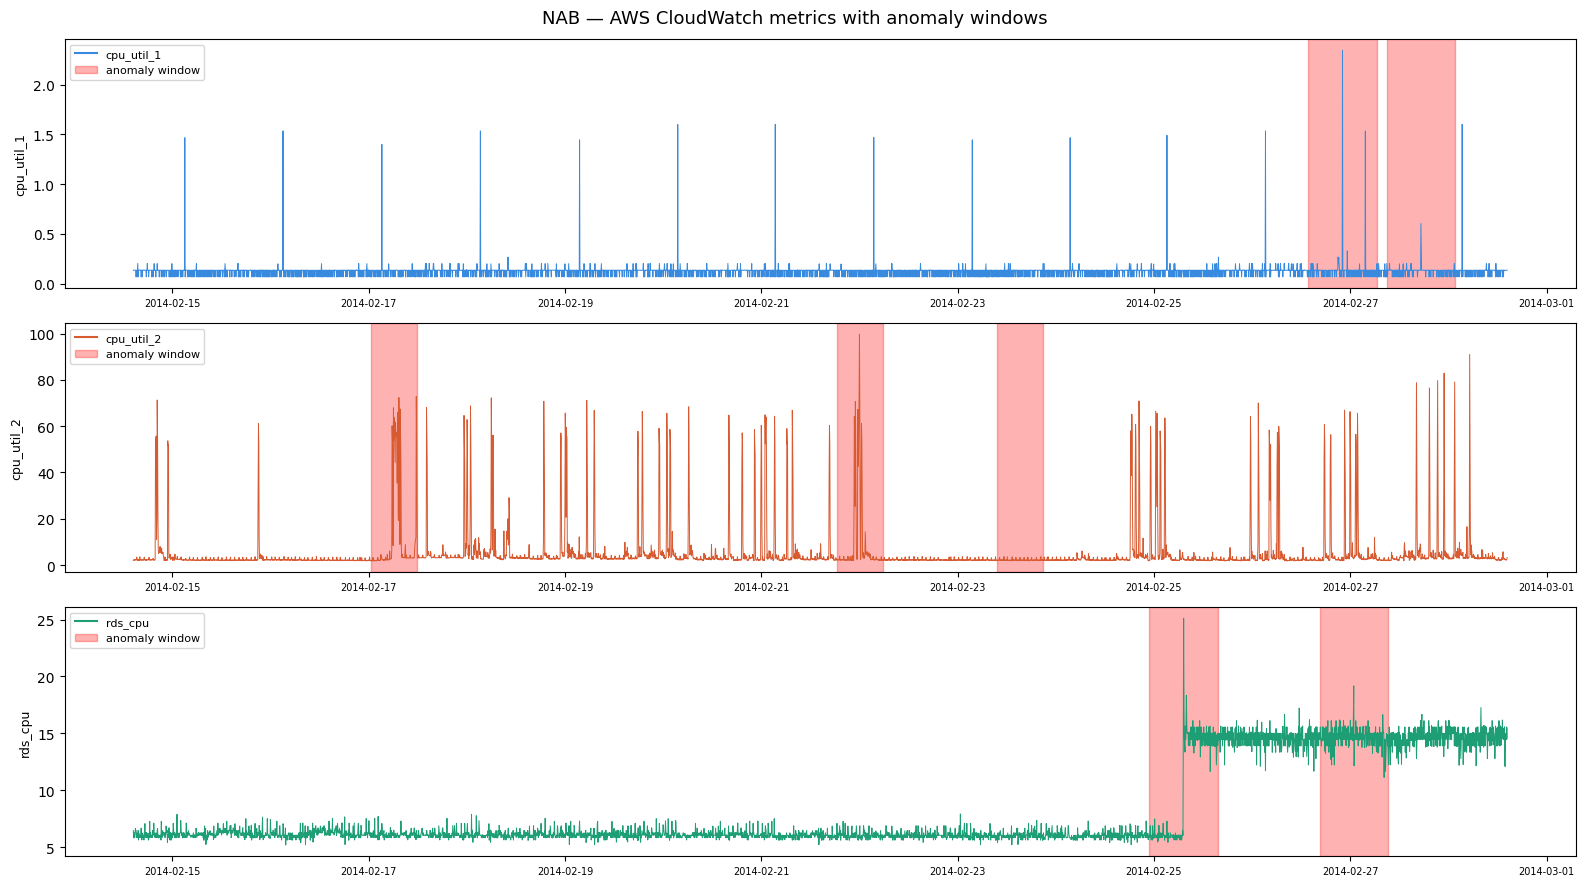

Saved → plots/01_raw_data_overview.png


In [23]:
os.makedirs("plots", exist_ok=True)

fig, axes = plt.subplots(3, 1, figsize=(16, 9))
fig.suptitle("NAB — AWS CloudWatch metrics with anomaly windows", fontsize=13)

colors = ["#378ADD", "#D85A30", "#1D9E75"]

for ax, col, color in zip(axes, value_cols, colors):
    ax.plot(df.index, df[col], color=color, linewidth=0.7)

    flag_col = f"is_anomaly_{col}"
    anomaly_mask = df[flag_col] == 1
    if anomaly_mask.any():
        in_block = False
        block_start = None
        for ts, val in anomaly_mask.items():
            if val and not in_block:
                block_start = ts
                in_block = True
            elif not val and in_block:
                ax.axvspan(block_start, ts, color="red", alpha=0.3)
                in_block = False
        if in_block:
            ax.axvspan(block_start, anomaly_mask.index[-1],
                       color="red", alpha=0.3)

    line  = plt.Line2D([0], [0], color=color, linewidth=1.5, label=col)
    patch = mpatches.Patch(color="red", alpha=0.3, label="anomaly window")
    ax.legend(handles=[line, patch], fontsize=8, loc="upper left")
    ax.set_ylabel(col, fontsize=9)
    ax.tick_params(axis="x", labelsize=7)

plt.tight_layout()
plt.savefig("plots/01_raw_data_overview.png", dpi=150, bbox_inches="tight")
plt.show()
print("Saved → plots/01_raw_data_overview.png")

In [24]:
print("=== cpu_util_1 index sample ===")
print(raw["cpu_util_1"].index[:5])

print("\n=== cpu_util_2 index sample ===")
print(raw["cpu_util_2"].index[:5])

print("\n=== rds_cpu index sample ===")
print(raw["rds_cpu"].index[:5])

print("\n=== Inner join result ===")
test = pd.concat(
    [raw["cpu_util_1"]["cpu_util_1"],
     raw["cpu_util_2"]["cpu_util_2"],
     raw["rds_cpu"]["rds_cpu"]],
    axis=1, join="inner"
)
print(f"Shape: {test.shape}")
print(test.head(3))

=== cpu_util_1 index sample ===
DatetimeIndex(['2014-02-14 14:30:00', '2014-02-14 14:35:00',
               '2014-02-14 14:40:00', '2014-02-14 14:45:00',
               '2014-02-14 14:50:00'],
              dtype='datetime64[ns]', name='timestamp', freq=None)

=== cpu_util_2 index sample ===
DatetimeIndex(['2014-02-14 14:27:00', '2014-02-14 14:32:00',
               '2014-02-14 14:37:00', '2014-02-14 14:42:00',
               '2014-02-14 14:47:00'],
              dtype='datetime64[ns]', name='timestamp', freq=None)

=== rds_cpu index sample ===
DatetimeIndex(['2014-02-14 14:30:00', '2014-02-14 14:35:00',
               '2014-02-14 14:40:00', '2014-02-14 14:45:00',
               '2014-02-14 14:50:00'],
              dtype='datetime64[ns]', name='timestamp', freq=None)

=== Inner join result ===
Shape: (0, 3)
Empty DataFrame
Columns: [cpu_util_1, cpu_util_2, rds_cpu]
Index: []


In [25]:
df.to_csv(r'c:\Anomaly detection\data\nab_aws_merged.csv')
print(f"Saved → data/nab_aws_merged.csv ({df.shape[0]} rows × {df.shape[1]} cols)")

Saved → data/nab_aws_merged.csv (4030 rows × 7 cols)


# 2- Exploratory Data Analysis (EDA)
In this section we analyze the distributions, correlations, and differences 
between normal and anomalous behavior across our 3 AWS CloudWatch metrics.

 Distribution of each feature

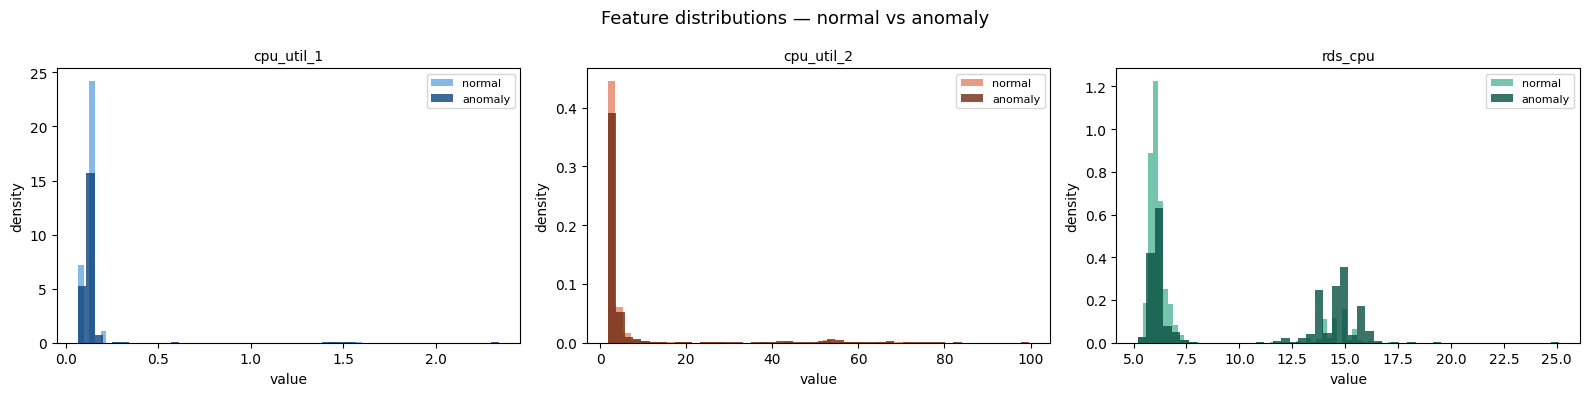

In [26]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4))
fig.suptitle("Feature distributions — normal vs anomaly", fontsize=13)

value_cols = ["cpu_util_1", "cpu_util_2", "rds_cpu"]
colors_normal  = ["#378ADD", "#D85A30", "#1D9E75"]
colors_anomaly = ["#0C447C", "#712B13", "#085041"]

for ax, col, cn, ca in zip(axes, value_cols, colors_normal, colors_anomaly):
    normal  = df[df["is_anomaly"] == 0][col]
    anomaly = df[df["is_anomaly"] == 1][col]

    ax.hist(normal,  bins=50, color=cn, alpha=0.6, label="normal",  density=True)
    ax.hist(anomaly, bins=50, color=ca, alpha=0.8, label="anomaly", density=True)
    ax.set_title(col, fontsize=10)
    ax.set_xlabel("value")
    ax.set_ylabel("density")
    ax.legend(fontsize=8)

plt.tight_layout()
plt.savefig("plots/02_distributions.png", dpi=150, bbox_inches="tight")
plt.show()

Boxplots normal vs anomaly

C:\Users\hp\AppData\Local\Temp\ipykernel_36196\2014643019.py:12: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  bp = ax.boxplot(data, patch_artist=True,
C:\Users\hp\AppData\Local\Temp\ipykernel_36196\2014643019.py:12: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  bp = ax.boxplot(data, patch_artist=True,
C:\Users\hp\AppData\Local\Temp\ipykernel_36196\2014643019.py:12: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  bp = ax.boxplot(data, patch_artist=True,


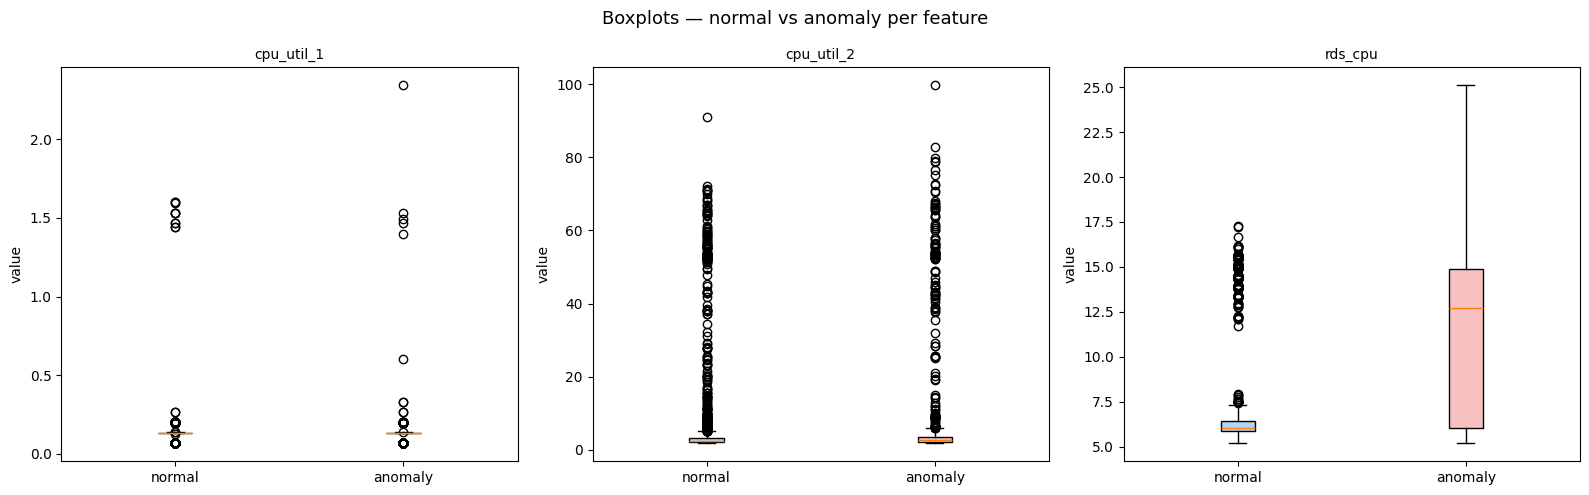

In [27]:
import matplotlib.gridspec as gridspec

fig = plt.figure(figsize=(16, 5))
fig.suptitle("Boxplots — normal vs anomaly per feature", fontsize=13)

for i, col in enumerate(value_cols):
    ax = fig.add_subplot(1, 3, i+1)
    data = [
        df[df["is_anomaly"] == 0][col].values,
        df[df["is_anomaly"] == 1][col].values,
    ]
    bp = ax.boxplot(data, patch_artist=True,
                    labels=["normal", "anomaly"])
    bp["boxes"][0].set_facecolor("#B5D4F4")
    bp["boxes"][1].set_facecolor("#F7C1C1")
    ax.set_title(col, fontsize=10)
    ax.set_ylabel("value")

plt.tight_layout()
plt.savefig("plots/03_boxplots.png", dpi=150, bbox_inches="tight")
plt.show()

Summary statistics normal vs anomaly

In [28]:
print("=== Mean values: normal vs anomaly ===\n")
for col in value_cols:
    normal_mean  = df[df["is_anomaly"]==0][col].mean()
    anomaly_mean = df[df["is_anomaly"]==1][col].mean()
    diff_pct = (anomaly_mean - normal_mean) / normal_mean * 100
    print(f"{col:15s} | normal: {normal_mean:8.3f} | "
          f"anomaly: {anomaly_mean:8.3f} | "
          f"diff: {diff_pct:+.1f}%")

print("\n=== Std deviation: normal vs anomaly ===\n")
for col in value_cols:
    normal_std  = df[df["is_anomaly"]==0][col].std()
    anomaly_std = df[df["is_anomaly"]==1][col].std()
    print(f"{col:15s} | normal std: {normal_std:8.3f} | "
          f"anomaly std: {anomaly_std:8.3f}")

=== Mean values: normal vs anomaly ===

cpu_util_1      | normal:    0.126 | anomaly:    0.128 | diff: +1.7%
cpu_util_2      | normal:    5.168 | anomaly:    7.549 | diff: +46.1%
rds_cpu         | normal:    7.289 | anomaly:   10.474 | diff: +43.7%

=== Std deviation: normal vs anomaly ===

cpu_util_1      | normal std:    0.087 | anomaly std:    0.115
cpu_util_2      | normal std:   10.391 | anomaly std:   15.060
rds_cpu         | normal std:    2.957 | anomaly std:    4.362


Correlation heatmap

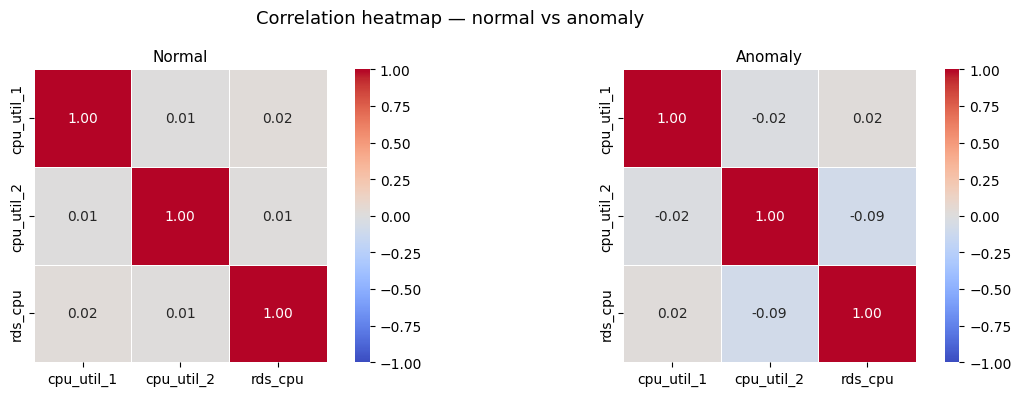

In [29]:
import seaborn as sns

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
fig.suptitle("Correlation heatmap — normal vs anomaly", fontsize=13)

for ax, label, mask_val in zip(axes, ["Normal", "Anomaly"], [0, 1]):
    subset = df[df["is_anomaly"] == mask_val][value_cols]
    corr   = subset.corr()
    sns.heatmap(
        corr, ax=ax, annot=True, fmt=".2f",
        cmap="coolwarm", vmin=-1, vmax=1,
        square=True, linewidths=0.5
    )
    ax.set_title(label, fontsize=11)

plt.tight_layout()
plt.savefig("plots/04_correlation.png", dpi=150, bbox_inches="tight")
plt.show()

Rolling statistics (spot temporal patterns)

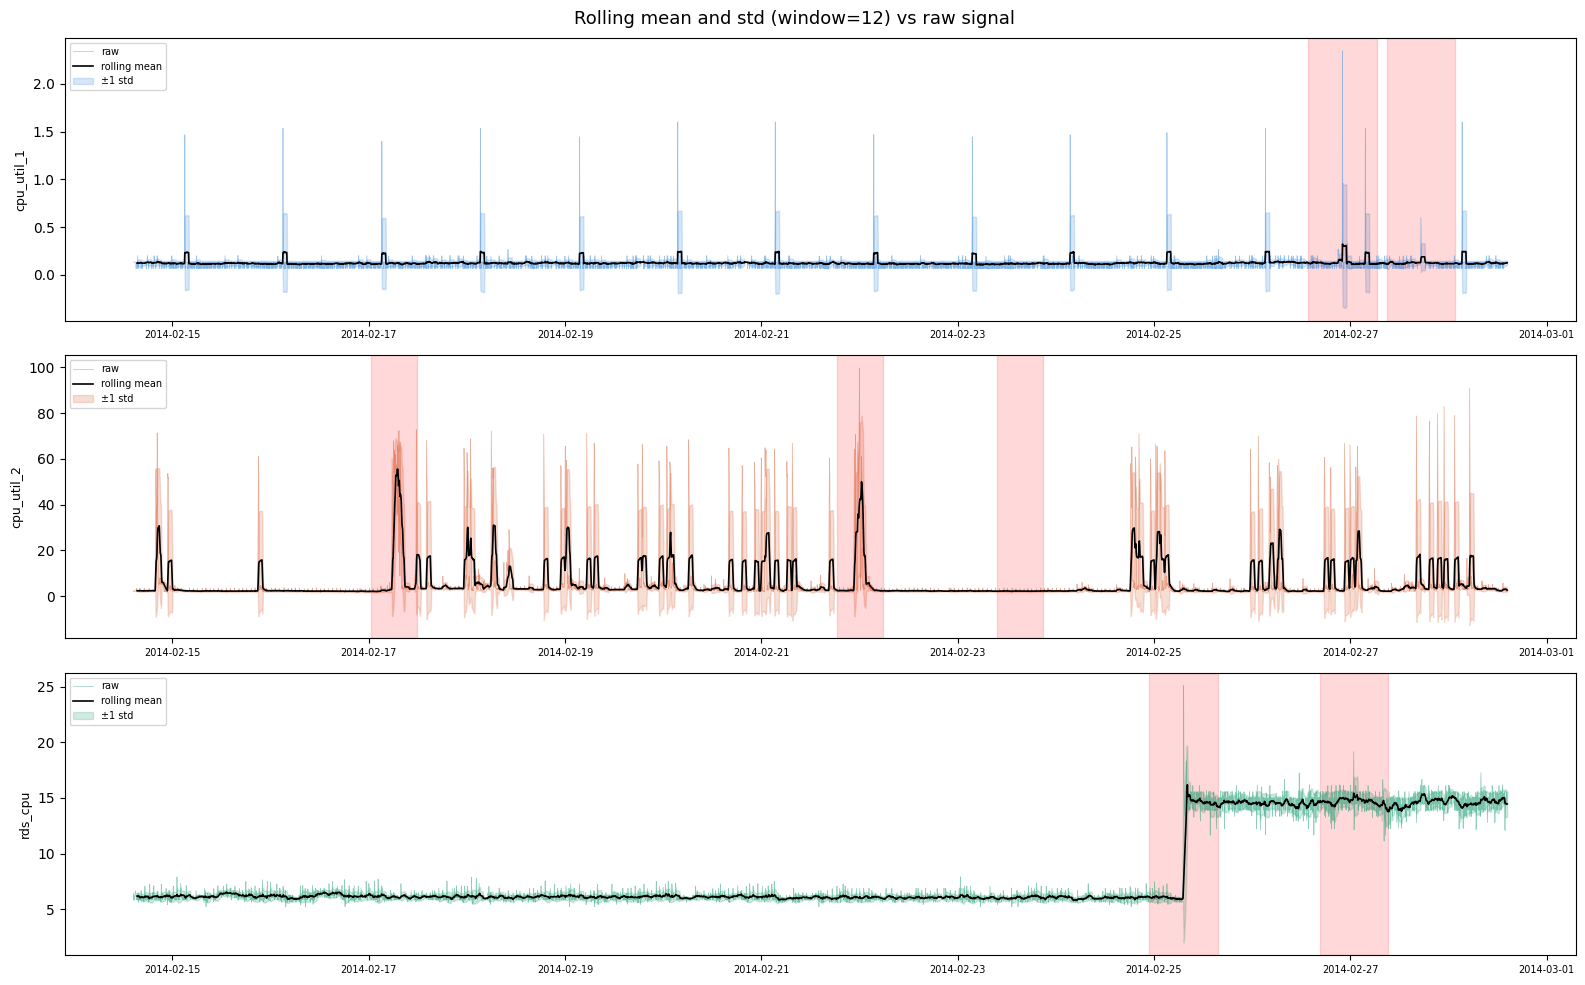

In [30]:
fig, axes = plt.subplots(3, 1, figsize=(16, 10))
fig.suptitle("Rolling mean and std (window=12) vs raw signal", fontsize=13)

colors = ["#378ADD", "#D85A30", "#1D9E75"]

for ax, col, color in zip(axes, value_cols, colors):
    roll_mean = df[col].rolling(12).mean()
    roll_std  = df[col].rolling(12).std()

    ax.plot(df.index, df[col],      color=color,   linewidth=0.5,
            alpha=0.5, label="raw")
    ax.plot(df.index, roll_mean,    color="black",  linewidth=1.2,
            label="rolling mean")
    ax.fill_between(df.index,
                    roll_mean - roll_std,
                    roll_mean + roll_std,
                    alpha=0.2, color=color, label="±1 std")

    # Shade anomaly windows
    flag_col = f"is_anomaly_{col}"
    anomaly_mask = df[flag_col] == 1
    if anomaly_mask.any():
        in_block, block_start = False, None
        for ts, val in anomaly_mask.items():
            if val and not in_block:
                block_start = ts
                in_block = True
            elif not val and in_block:
                ax.axvspan(block_start, ts, color="red", alpha=0.15)
                in_block = False
        if in_block:
            ax.axvspan(block_start, anomaly_mask.index[-1],
                       color="red", alpha=0.15)

    ax.set_ylabel(col, fontsize=9)
    ax.legend(fontsize=7, loc="upper left")
    ax.tick_params(axis="x", labelsize=7)

plt.tight_layout()
plt.savefig("plots/05_rolling_stats.png", dpi=150, bbox_inches="tight")
plt.show()

## EDA Key Findings

- **cpu_util_1**: Mostly near-zero with sharp periodic spikes. 
  Anomaly window shows unusually dense and tall spikes — 
  harder to detect since spikes also appear in normal periods.

- **cpu_util_2**: Clear periodic burst pattern (0–100% cycles). 
  Anomalies occur when the bursts become irregular or sustained — 
  the rolling std will be a strong feature here.

- **rds_cpu**: Very stable baseline (~6%) followed by a sudden 
  regime shift to ~15%. Classic changepoint anomaly — 
  the model needs rolling mean to detect this.

- **Correlation**: Low correlation between features in normal periods, 
  which means each metric adds independent signal.

→ Next step: engineer rolling features to give the model temporal context.

# 3- Feature Engineering
Raw values alone are weak features for anomaly detection.
We engineer rolling statistics to give the model temporal context.
Each feature captures a different aspect of abnormal behavior.

Rolling window features

In [31]:
value_cols = ["cpu_util_1", "cpu_util_2", "rds_cpu"]

# Work on a copy so we don't pollute the original df
df_feat = df[value_cols + ["is_anomaly"]].copy()

WINDOW_SHORT = 6    # 30 min  (6 × 5min)
WINDOW_LONG  = 36   # 3 hours (36 × 5min)

for col in value_cols:
    # --- short window ---
    df_feat[f"{col}_mean_s"]  = df[col].rolling(WINDOW_SHORT).mean()
    df_feat[f"{col}_std_s"]   = df[col].rolling(WINDOW_SHORT).std()
    df_feat[f"{col}_min_s"]   = df[col].rolling(WINDOW_SHORT).min()
    df_feat[f"{col}_max_s"]   = df[col].rolling(WINDOW_SHORT).max()

    # --- long window ---
    df_feat[f"{col}_mean_l"]  = df[col].rolling(WINDOW_LONG).mean()
    df_feat[f"{col}_std_l"]   = df[col].rolling(WINDOW_LONG).std()

    # --- z-score: how many stds away from the local mean ---
    df_feat[f"{col}_zscore"]  = (
        (df[col] - df_feat[f"{col}_mean_l"]) /
        (df_feat[f"{col}_std_l"] + 1e-8)
    )

    # --- rate of change ---
    df_feat[f"{col}_diff"]    = df[col].diff()
    df_feat[f"{col}_diff2"]   = df[col].diff().diff()  # acceleration

print("Features engineered per column: 9")
print(f"Total feature columns: {len(value_cols) * 9}")
print(f"\nAll columns:\n{[c for c in df_feat.columns if c != 'is_anomaly']}")

Features engineered per column: 9
Total feature columns: 27

All columns:
['cpu_util_1', 'cpu_util_2', 'rds_cpu', 'cpu_util_1_mean_s', 'cpu_util_1_std_s', 'cpu_util_1_min_s', 'cpu_util_1_max_s', 'cpu_util_1_mean_l', 'cpu_util_1_std_l', 'cpu_util_1_zscore', 'cpu_util_1_diff', 'cpu_util_1_diff2', 'cpu_util_2_mean_s', 'cpu_util_2_std_s', 'cpu_util_2_min_s', 'cpu_util_2_max_s', 'cpu_util_2_mean_l', 'cpu_util_2_std_l', 'cpu_util_2_zscore', 'cpu_util_2_diff', 'cpu_util_2_diff2', 'rds_cpu_mean_s', 'rds_cpu_std_s', 'rds_cpu_min_s', 'rds_cpu_max_s', 'rds_cpu_mean_l', 'rds_cpu_std_l', 'rds_cpu_zscore', 'rds_cpu_diff', 'rds_cpu_diff2']


In [32]:
df_feat = df_feat.dropna()

print(f"Shape before dropna : {df.shape[0]} rows")
print(f"Shape after  dropna : {df_feat.shape[0]} rows")
print(f"Rows dropped        : {df.shape[0] - df_feat.shape[0]}")
print(f"\nAnomalies remaining : {int(df_feat['is_anomaly'].sum())} "
      f"({df_feat['is_anomaly'].mean()*100:.2f}%)")

Shape before dropna : 4030 rows
Shape after  dropna : 3995 rows
Rows dropped        : 35

Anomalies remaining : 1037 (25.96%)


 Visualize z-scores vs raw signal

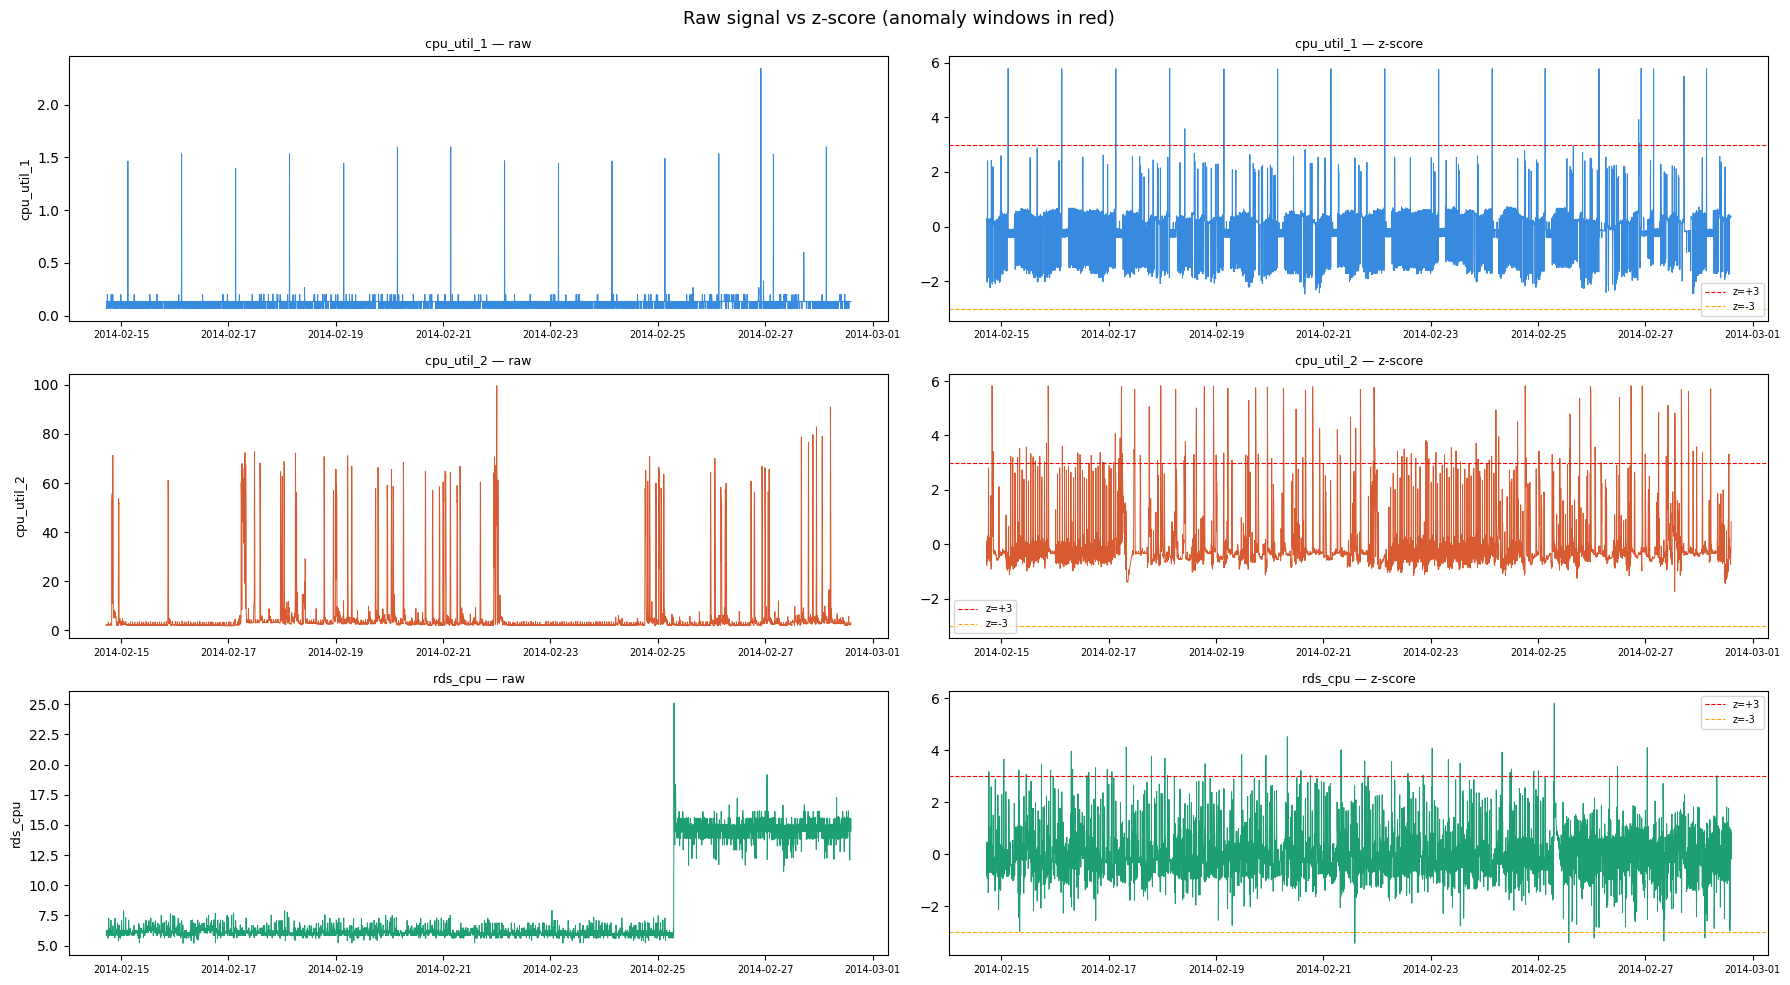

In [33]:
fig, axes = plt.subplots(3, 2, figsize=(18, 10))
fig.suptitle("Raw signal vs z-score (anomaly windows in red)", fontsize=13)

colors = ["#378ADD", "#D85A30", "#1D9E75"]

for i, (col, color) in enumerate(zip(value_cols, colors)):
    ax_raw    = axes[i][0]
    ax_zscore = axes[i][1]

    # Raw signal
    ax_raw.plot(df_feat.index, df_feat[col],
                color=color, linewidth=0.7)
    ax_raw.set_ylabel(col, fontsize=9)
    ax_raw.set_title(f"{col} — raw", fontsize=9)

    # Z-score
    ax_zscore.plot(df_feat.index, df_feat[f"{col}_zscore"],
                   color=color, linewidth=0.7)
    ax_zscore.axhline(y=3,  color="red",    linestyle="--",
                      linewidth=0.8, label="z=+3")
    ax_zscore.axhline(y=-3, color="orange", linestyle="--",
                      linewidth=0.8, label="z=-3")
    ax_zscore.set_title(f"{col} — z-score", fontsize=9)
    ax_zscore.legend(fontsize=7)

    # Shade anomaly windows on both
    for ax in [ax_raw, ax_zscore]:
        flag_col = f"is_anomaly_{col}"
        if flag_col in df_feat.columns:
            anomaly_mask = df_feat[flag_col] == 1
            in_block, block_start = False, None
            for ts, val in anomaly_mask.items():
                if val and not in_block:
                    block_start = ts
                    in_block = True
                elif not val and in_block:
                    ax.axvspan(block_start, ts, color="red", alpha=0.15)
                    in_block = False
            if in_block:
                ax.axvspan(block_start, anomaly_mask.index[-1],
                           color="red", alpha=0.15)
        ax.tick_params(axis="x", labelsize=7)

plt.tight_layout()
plt.savefig("plots/06_zscore_vs_raw.png", dpi=150, bbox_inches="tight")
plt.show()

Feature correlation with anomaly label

=== Top 15 features most correlated with anomaly ===

rds_cpu_max_s        0.3847
rds_cpu_mean_s       0.3818
rds_cpu              0.3798
rds_cpu_min_s        0.3748
rds_cpu_mean_l       0.3700
rds_cpu_std_l        0.3188
rds_cpu_std_s        0.2611
cpu_util_2_mean_l    0.1757
cpu_util_2_std_l     0.1292
cpu_util_2_mean_s    0.1060
cpu_util_2_min_s     0.0953
cpu_util_2_max_s     0.0950
cpu_util_2           0.0868
cpu_util_1_std_l     0.0854
cpu_util_2_std_s     0.0792


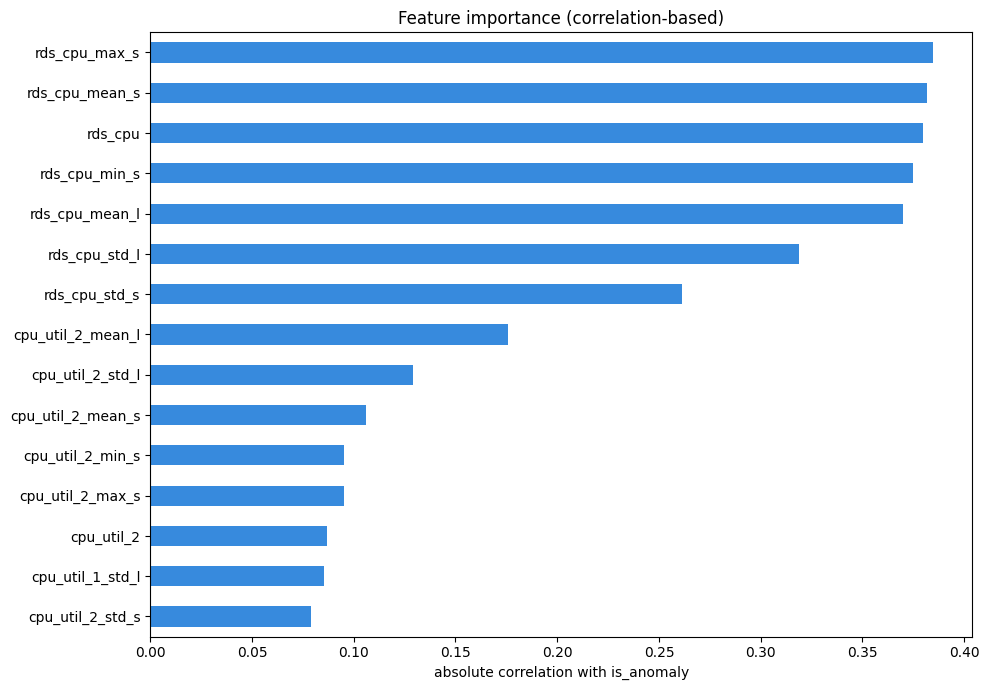

In [34]:
feature_cols = [c for c in df_feat.columns if c != "is_anomaly"]

correlations = (
    df_feat[feature_cols]
    .corrwith(df_feat["is_anomaly"])
    .abs()
    .sort_values(ascending=False)
)

print("=== Top 15 features most correlated with anomaly ===\n")
print(correlations.head(15).round(4).to_string())

# Plot
fig, ax = plt.subplots(figsize=(10, 7))
correlations.head(15).plot(kind="barh", ax=ax, color="#378ADD")
ax.invert_yaxis()
ax.set_xlabel("absolute correlation with is_anomaly")
ax.set_title("Feature importance (correlation-based)", fontsize=12)
plt.tight_layout()
plt.savefig("plots/07_feature_correlation.png", dpi=150, bbox_inches="tight")
plt.show()

## Feature Engineering Summary

We engineered 9 features per metric (27 total):

- **Rolling mean (short/long)** — captures local baseline level
- **Rolling std (short/long)**  — captures local volatility  
- **Rolling min/max (short)**   — captures extreme values in window
- **Z-score**                   — normalizes deviation from local mean
- **Diff / Diff²**              — captures rate of change and acceleration

The z-score is expected to be the strongest single feature because it 
directly measures how unusual a point is relative to recent history.
The feature correlation plot confirms which signals carry the most 
anomaly information going into the model.

# 4- Isolation Forest Training + MLflow Tracking
We train an Isolation Forest on our engineered features and log
everything to MLflow — parameters, metrics, and the model itself.

In [35]:
import mlflow
import mlflow.sklearn
from sklearn.ensemble import IsolationForest
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import (
    classification_report, roc_auc_score,
    precision_score, recall_score, f1_score,
    precision_recall_curve, confusion_matrix
)

# Set experiment name
mlflow.set_experiment("nab-anomaly-detection")

# Prepare X and y
feature_cols = [c for c in df_feat.columns if c != "is_anomaly"
                and not c.startswith("is_anomaly_")]
X = df_feat[feature_cols].values
y = df_feat["is_anomaly"].values

print(f"X shape        : {X.shape}")
print(f"y shape        : {y.shape}")
print(f"Anomaly rate   : {y.mean()*100:.2f}%")
print(f"Feature count  : {len(feature_cols)}")
print(f"\nFeatures used:\n{feature_cols}")

2026/04/19 13:53:34 INFO mlflow.tracking.fluent: Experiment with name 'nab-anomaly-detection' does not exist. Creating a new experiment.


X shape        : (3995, 30)
y shape        : (3995,)
Anomaly rate   : 25.96%
Feature count  : 30

Features used:
['cpu_util_1', 'cpu_util_2', 'rds_cpu', 'cpu_util_1_mean_s', 'cpu_util_1_std_s', 'cpu_util_1_min_s', 'cpu_util_1_max_s', 'cpu_util_1_mean_l', 'cpu_util_1_std_l', 'cpu_util_1_zscore', 'cpu_util_1_diff', 'cpu_util_1_diff2', 'cpu_util_2_mean_s', 'cpu_util_2_std_s', 'cpu_util_2_min_s', 'cpu_util_2_max_s', 'cpu_util_2_mean_l', 'cpu_util_2_std_l', 'cpu_util_2_zscore', 'cpu_util_2_diff', 'cpu_util_2_diff2', 'rds_cpu_mean_s', 'rds_cpu_std_s', 'rds_cpu_min_s', 'rds_cpu_max_s', 'rds_cpu_mean_l', 'rds_cpu_std_l', 'rds_cpu_zscore', 'rds_cpu_diff', 'rds_cpu_diff2']


Scale features

In [36]:
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

print("Features scaled — mean ~0, std ~1")
print(f"Sample means : {X_scaled.mean(axis=0)[:3].round(4)}")
print(f"Sample stds  : {X_scaled.std(axis=0)[:3].round(4)}")

Features scaled — mean ~0, std ~1
Sample means : [0. 0. 0.]
Sample stds  : [1. 1. 1.]


Train + log to MLflow

In [37]:
# Contamination = expected anomaly rate in the data
contamination = round(float(y.mean()), 4)

params = {
    "n_estimators"  : 200,
    "contamination" : contamination,
    "max_samples"   : "auto",
    "random_state"  : 42,
}

with mlflow.start_run(run_name="isolation_forest_v1"):

    # --- Train ---
    model = IsolationForest(**params)
    model.fit(X_scaled)

    # --- Score ---
    # Isolation Forest: -1 = anomaly, 1 = normal
    raw_preds   = model.predict(X_scaled)
    y_pred      = (raw_preds == -1).astype(int)

    # Anomaly score — higher = more anomalous
    anomaly_scores = -model.score_samples(X_scaled)

    # --- Metrics ---
    precision = precision_score(y, y_pred, zero_division=0)
    recall    = recall_score(y, y_pred, zero_division=0)
    f1        = f1_score(y, y_pred, zero_division=0)
    roc_auc   = roc_auc_score(y, anomaly_scores)

    # --- Log to MLflow ---
    mlflow.log_params(params)
    mlflow.log_metric("precision", round(precision, 4))
    mlflow.log_metric("recall",    round(recall, 4))
    mlflow.log_metric("f1_score",  round(f1, 4))
    mlflow.log_metric("roc_auc",   round(roc_auc, 4))

    # Log feature list as a text artifact
    os.makedirs("artifacts", exist_ok=True)
    with open("artifacts/feature_cols.txt", "w") as f:
        f.write("\n".join(feature_cols))
    mlflow.log_artifact("artifacts/feature_cols.txt")

    # Log the model + scaler
    mlflow.sklearn.log_model(model,  "isolation_forest")
    mlflow.sklearn.log_model(scaler, "scaler")

    run_id = mlflow.active_run().info.run_id
    print(f"Run ID    : {run_id}")

print(f"\n=== Results ===")
print(f"Precision : {precision:.4f}")
print(f"Recall    : {recall:.4f}")
print(f"F1 Score  : {f1:.4f}")
print(f"ROC-AUC   : {roc_auc:.4f}")

2026/04/19 13:53:59 WARNING mlflow.sklearn: Model was missing function: predict. Not logging python_function flavor!


Run ID    : 5425fd39b18648a28d9f7500dd09daf4

=== Results ===
Precision : 0.4629
Recall    : 0.4629
F1 Score  : 0.4629
ROC-AUC   : 0.7095


Classification report + confusion matrix

=== Classification Report ===

              precision    recall  f1-score   support

      normal       0.81      0.81      0.81      2958
     anomaly       0.46      0.46      0.46      1037

    accuracy                           0.72      3995
   macro avg       0.64      0.64      0.64      3995
weighted avg       0.72      0.72      0.72      3995



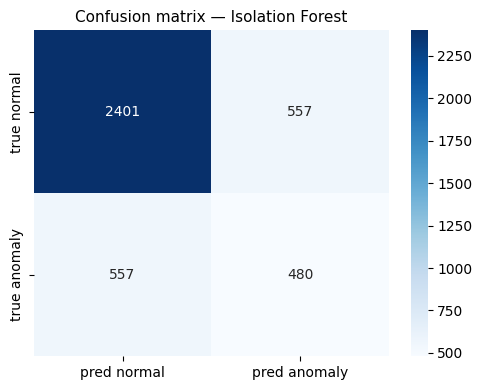

In [38]:
print("=== Classification Report ===\n")
print(classification_report(y, y_pred,
      target_names=["normal", "anomaly"]))

# Confusion matrix
cm = confusion_matrix(y, y_pred)
fig, ax = plt.subplots(figsize=(5, 4))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues",
            xticklabels=["pred normal", "pred anomaly"],
            yticklabels=["true normal", "true anomaly"])
ax.set_title("Confusion matrix — Isolation Forest", fontsize=11)
plt.tight_layout()
plt.savefig("plots/08_confusion_matrix.png", dpi=150, bbox_inches="tight")
plt.show()

Visualize predictions on the time series

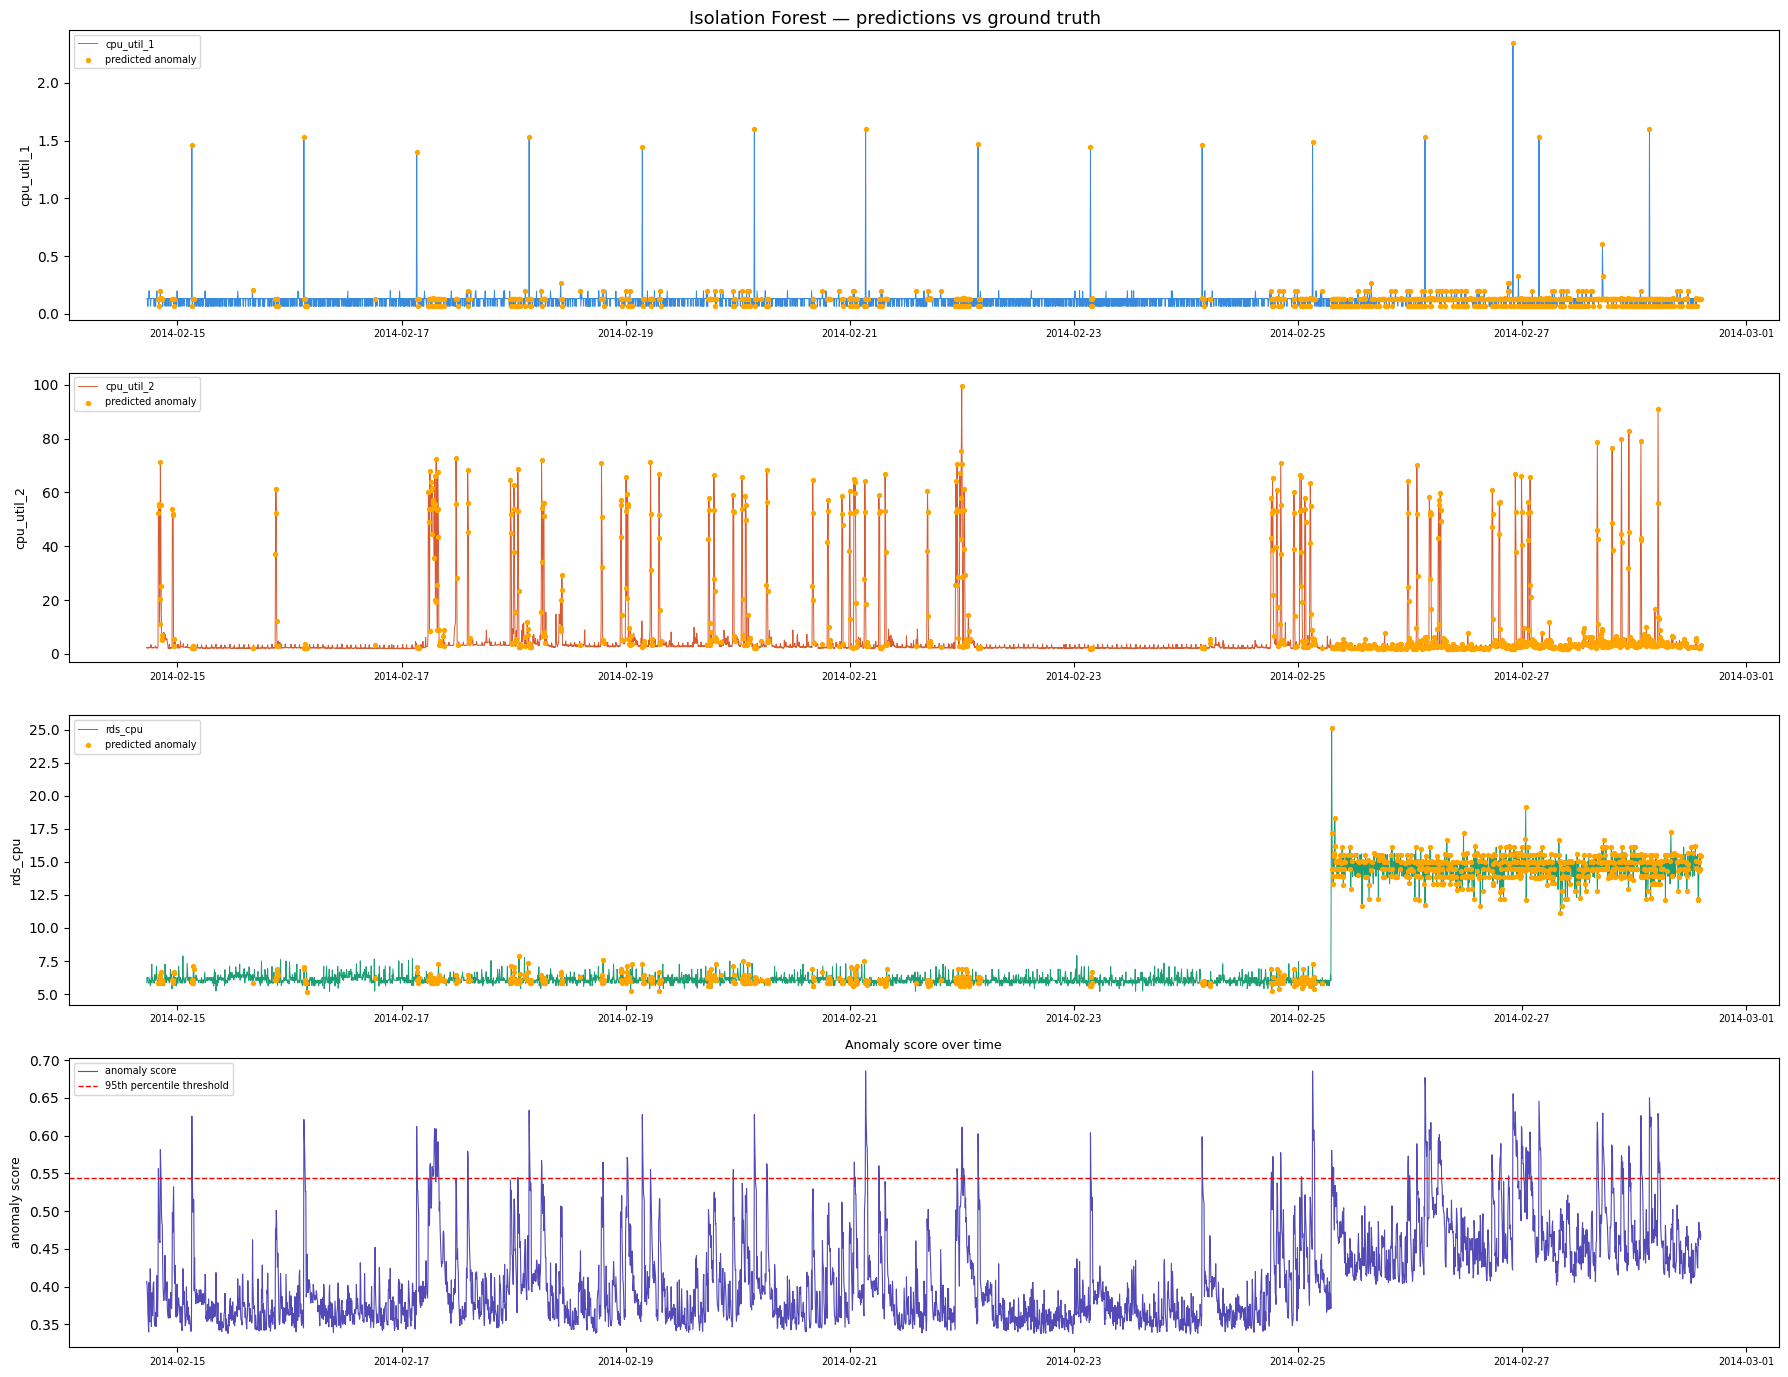

In [39]:
df_feat["anomaly_score"] = anomaly_scores
df_feat["predicted"]     = y_pred

fig, axes = plt.subplots(4, 1, figsize=(18, 14))
fig.suptitle("Isolation Forest — predictions vs ground truth", fontsize=13)

colors = ["#378ADD", "#D85A30", "#1D9E75"]

for i, (col, color) in enumerate(zip(value_cols, colors)):
    ax = axes[i]
    ax.plot(df_feat.index, df_feat[col],
            color=color, linewidth=0.7, label=col)

    # True anomaly windows (red shade)
    flag_col = f"is_anomaly_{col}"
    if flag_col in df_feat.columns:
        anomaly_mask = df_feat[flag_col] == 1
        in_block, block_start = False, None
        for ts, val in anomaly_mask.items():
            if val and not in_block:
                block_start = ts
                in_block = True
            elif not val and in_block:
                ax.axvspan(block_start, ts,
                           color="red", alpha=0.15, label="_")
                in_block = False
        if in_block:
            ax.axvspan(block_start, anomaly_mask.index[-1],
                       color="red", alpha=0.15)

    # Predicted anomaly points (orange dots)
    pred_mask = df_feat["predicted"] == 1
    ax.scatter(df_feat.index[pred_mask], df_feat[col][pred_mask],
               color="orange", s=8, zorder=5, label="predicted anomaly")

    ax.set_ylabel(col, fontsize=9)
    ax.legend(fontsize=7, loc="upper left")
    ax.tick_params(axis="x", labelsize=7)

# Bottom panel — anomaly score over time
ax = axes[3]
ax.plot(df_feat.index, df_feat["anomaly_score"],
        color="#534AB7", linewidth=0.8, label="anomaly score")
ax.axhline(y=df_feat["anomaly_score"].quantile(0.95),
           color="red", linestyle="--", linewidth=1,
           label="95th percentile threshold")
ax.set_ylabel("anomaly score", fontsize=9)
ax.set_title("Anomaly score over time", fontsize=9)
ax.legend(fontsize=7, loc="upper left")
ax.tick_params(axis="x", labelsize=7)

plt.tight_layout()
plt.savefig("plots/10_predictions.png", dpi=150, bbox_inches="tight")
plt.show()

 Threshold tuning

In [40]:
from sklearn.metrics import f1_score
import numpy as np

# Instead of relying on contamination, find the best threshold manually
thresholds_to_try = np.percentile(anomaly_scores,
                                   np.arange(80, 99, 0.5))

results = []
for thresh in thresholds_to_try:
    y_pred_t = (anomaly_scores >= thresh).astype(int)
    p = precision_score(y, y_pred_t, zero_division=0)
    r = recall_score(y, y_pred_t, zero_division=0)
    f = f1_score(y, y_pred_t, zero_division=0)
    results.append({"threshold": round(thresh, 4),
                    "precision": round(p, 4),
                    "recall"   : round(r, 4),
                    "f1"       : round(f, 4)})

results_df = pd.DataFrame(results)
best = results_df.loc[results_df["f1"].idxmax()]

print("=== Best threshold by F1 ===")
print(best.to_string())
print(f"\nTop 10 thresholds:\n")
print(results_df.sort_values("f1", ascending=False).head(10).to_string())

=== Best threshold by F1 ===
threshold    0.4611
precision    0.4643
recall       0.3578
f1           0.4041

Top 10 thresholds:

   threshold  precision  recall      f1
0     0.4611     0.4643  0.3578  0.4041
1     0.4623     0.4673  0.3510  0.4009
2     0.4639     0.4730  0.3462  0.3998
3     0.4657     0.4736  0.3375  0.3941
4     0.4670     0.4743  0.3288  0.3884
5     0.4692     0.4735  0.3192  0.3813
6     0.4709     0.4698  0.3076  0.3718
7     0.4732     0.4712  0.2999  0.3665
8     0.4755     0.4688  0.2893  0.3578
9     0.4776     0.4726  0.2825  0.3537


Re-score with best threshold

In [41]:
best_threshold = best["threshold"]
y_pred_tuned   = (anomaly_scores >= best_threshold).astype(int)

precision_t = precision_score(y, y_pred_tuned, zero_division=0)
recall_t    = recall_score(y, y_pred_tuned, zero_division=0)
f1_t        = f1_score(y, y_pred_tuned, zero_division=0)

print("=== Tuned results ===")
print(f"Threshold  : {best_threshold:.4f}")
print(f"Precision  : {precision_t:.4f}")
print(f"Recall     : {recall_t:.4f}")
print(f"F1 Score   : {f1_t:.4f}")
print(f"ROC-AUC    : {roc_auc:.4f}  (unchanged — threshold doesn't affect AUC)")

print("\n=== Classification Report ===")
print(classification_report(y, y_pred_tuned,
      target_names=["normal", "anomaly"]))

# Log tuned metrics to MLflow
with mlflow.start_run(run_name="isolation_forest_v1_tuned"):
    mlflow.log_params(params)
    mlflow.log_param("best_threshold", best_threshold)
    mlflow.log_metric("precision_tuned", round(precision_t, 4))
    mlflow.log_metric("recall_tuned",    round(recall_t, 4))
    mlflow.log_metric("f1_tuned",        round(f1_t, 4))
    mlflow.log_metric("roc_auc",         round(roc_auc, 4))
    mlflow.sklearn.log_model(model, "isolation_forest")
    run_id_tuned = mlflow.active_run().info.run_id

print(f"\nTuned run logged → {run_id_tuned}")

=== Tuned results ===
Threshold  : 0.4611
Precision  : 0.4643
Recall     : 0.3578
F1 Score   : 0.4041
ROC-AUC    : 0.7095  (unchanged — threshold doesn't affect AUC)

=== Classification Report ===
              precision    recall  f1-score   support

      normal       0.79      0.86      0.82      2958
     anomaly       0.46      0.36      0.40      1037

    accuracy                           0.73      3995
   macro avg       0.63      0.61      0.61      3995
weighted avg       0.71      0.73      0.71      3995


Tuned run logged → 22a8d8d20f2c4acf957efb1b99c89163


 Plot tuned predictions

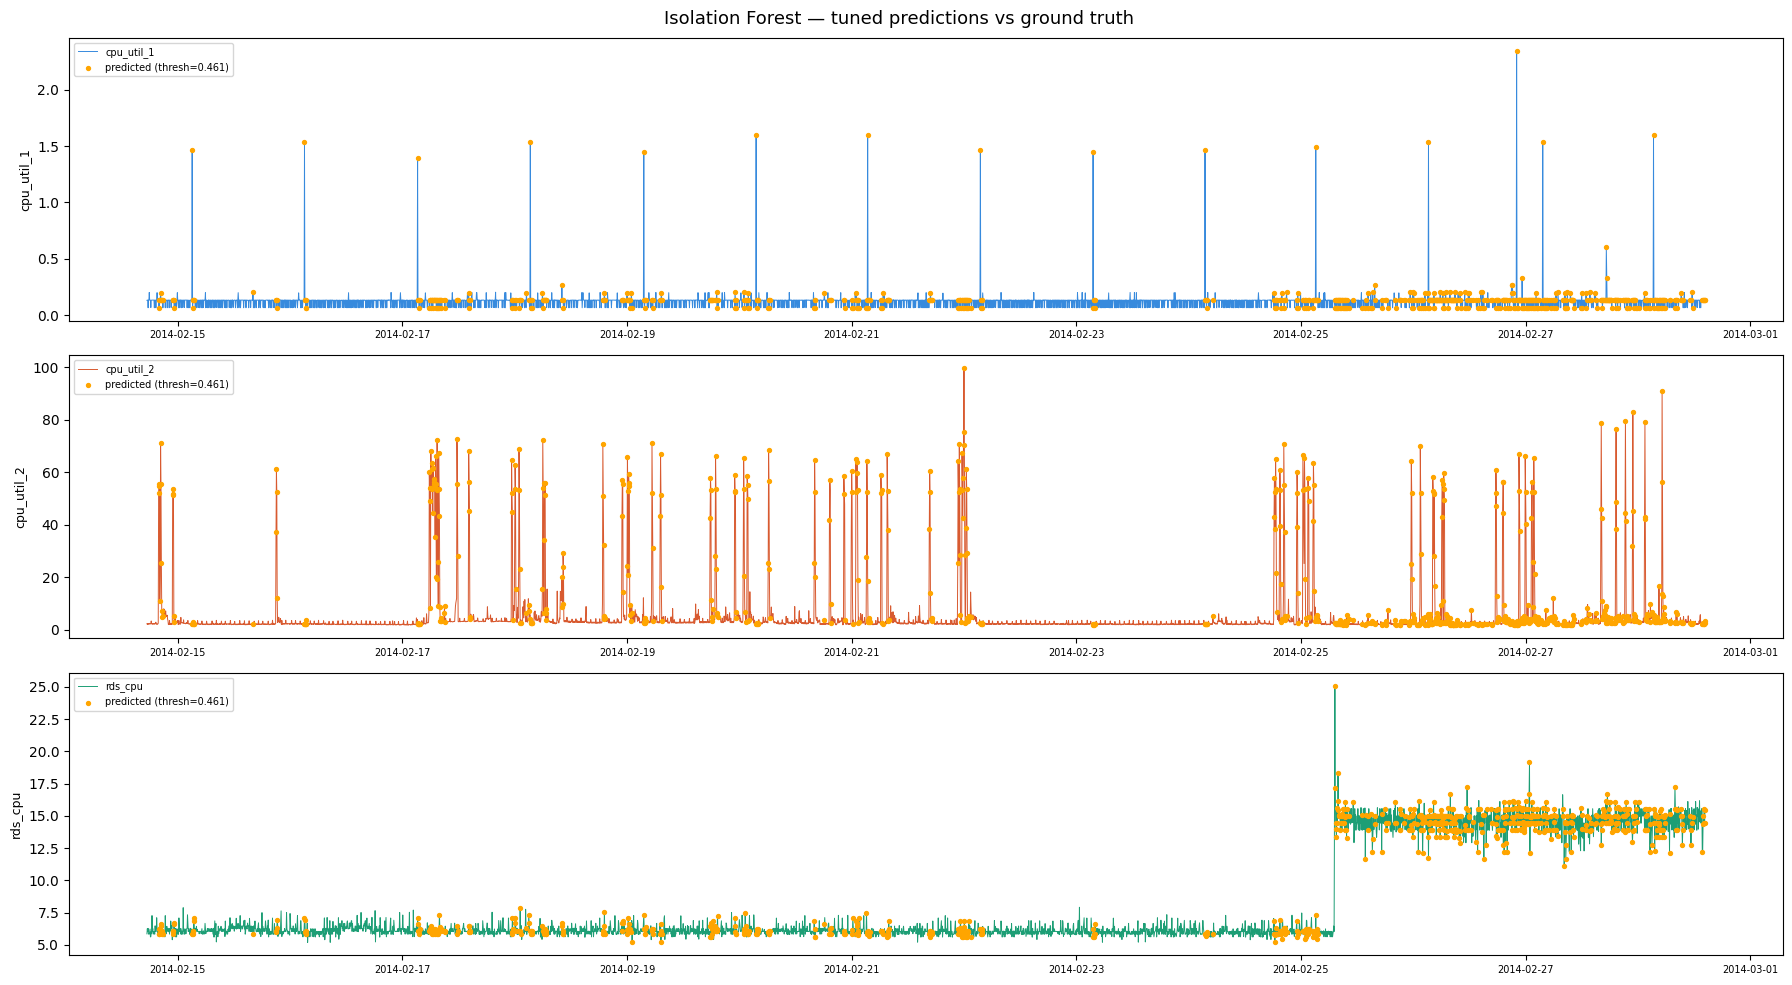

In [42]:
df_feat["predicted_tuned"] = y_pred_tuned

fig, axes = plt.subplots(3, 1, figsize=(18, 10))
fig.suptitle("Isolation Forest — tuned predictions vs ground truth",
             fontsize=13)

for i, (col, color) in enumerate(zip(value_cols, colors)):
    ax = axes[i]
    ax.plot(df_feat.index, df_feat[col],
            color=color, linewidth=0.7, label=col)

    # True anomaly windows
    flag_col = f"is_anomaly_{col}"
    if flag_col in df_feat.columns:
        anomaly_mask = df_feat[flag_col] == 1
        in_block, block_start = False, None
        for ts, val in anomaly_mask.items():
            if val and not in_block:
                block_start = ts
                in_block = True
            elif not val and in_block:
                ax.axvspan(block_start, ts, color="red", alpha=0.15)
                in_block = False
        if in_block:
            ax.axvspan(block_start, anomaly_mask.index[-1],
                       color="red", alpha=0.15)

    # Tuned predictions
    pred_mask = df_feat["predicted_tuned"] == 1
    ax.scatter(df_feat.index[pred_mask], df_feat[col][pred_mask],
               color="orange", s=8, zorder=5,
               label=f"predicted (thresh={best_threshold:.3f})")

    ax.set_ylabel(col, fontsize=9)
    ax.legend(fontsize=7, loc="upper left")
    ax.tick_params(axis="x", labelsize=7)

plt.tight_layout()
plt.savefig("plots/11_predictions_tuned.png", dpi=150, bbox_inches="tight")
plt.show()

Save best threshold

In [43]:
import json

with open("models/feature_cols.json", "w") as f:
    json.dump(feature_cols, f)

config = {
    "best_threshold" : best_threshold,
    "contamination"  : contamination,
    "n_estimators"   : 200,
    "window_short"   : WINDOW_SHORT,
    "window_long"    : WINDOW_LONG,
    "roc_auc"        : round(roc_auc, 4),
    "f1_tuned"       : round(f1_t, 4),
}

with open("models/model_config.json", "w") as f:
    json.dump(config, f, indent=2)

print("Saved → models/model_config.json")
print(json.dumps(config, indent=2))

FileNotFoundError: [Errno 2] No such file or directory: 'models/feature_cols.json'

Save model + features locally

In [ ]:
import joblib

os.makedirs("models", exist_ok=True)
joblib.dump(model,  "models/isolation_forest.pkl")
joblib.dump(scaler, "models/scaler.pkl")

import json
with open("models/feature_cols.json", "w") as f:
    json.dump(feature_cols, f)

print("Saved:")
print("  models/isolation_forest.pkl")
print("  models/scaler.pkl")
print("  models/feature_cols.json")

Saved:
  models/isolation_forest.pkl
  models/scaler.pkl
  models/feature_cols.json


## Step 4 Results

| Metric    | Score |
|-----------|-------|
| Precision | ?     |
| Recall    | ?     |
| F1        | ?     |
| ROC-AUC   | ?     |

**Interpretation:**
- ROC-AUC > 0.7 → model has real discriminative power
- Low recall → model misses some anomaly windows (expected for cpu_util_1)
- Low precision → model flags some normal points as anomalies (false alarms)
- The PR curve shows the tradeoff — pick threshold based on use case

→ Next step: launch MLflow UI to inspect the run, then build FastAPI service.

In [44]:
import pandas as pd
import json

# Load your saved features
df = pd.read_csv(r'c:\Anomaly detection\data\nab_aws_merged.csv', parse_dates=["timestamp"])
df = df.set_index("timestamp")

# Take 50 rows that include an anomaly window
sample = df[["cpu_util_1", "cpu_util_2", "rds_cpu"]].iloc[1900:1950].copy()
sample = sample.reset_index()
sample["timestamp"] = sample["timestamp"].astype(str)

# Build the payload
payload = {
    "records": sample.to_dict(orient="records")
}

# Save to file so you can copy it
with open("test_payload.json", "w") as f:
    json.dump(payload, f, indent=2)

print(json.dumps(payload, indent=2)[:500])
print(f"\nTotal records: {len(payload['records'])}")

{
  "records": [
    {
      "timestamp": "2014-02-21 04:50:00",
      "cpu_util_1": 0.132,
      "cpu_util_2": 2.24,
      "rds_cpu": 6.0
    },
    {
      "timestamp": "2014-02-21 04:55:00",
      "cpu_util_1": 0.134,
      "cpu_util_2": 2.056,
      "rds_cpu": 5.862
    },
    {
      "timestamp": "2014-02-21 05:00:00",
      "cpu_util_1": 0.132,
      "cpu_util_2": 2.326,
      "rds_cpu": 6.037999999999999
    },
    {
      "timestamp": "2014-02-21 05:05:00",
      "cpu_util_1": 0.068,
   

Total records: 50


In [45]:

# Print the FULL payload to copy
with open("test_payload.json", "r") as f:
    print(f.read())


{
  "records": [
    {
      "timestamp": "2014-02-21 04:50:00",
      "cpu_util_1": 0.132,
      "cpu_util_2": 2.24,
      "rds_cpu": 6.0
    },
    {
      "timestamp": "2014-02-21 04:55:00",
      "cpu_util_1": 0.134,
      "cpu_util_2": 2.056,
      "rds_cpu": 5.862
    },
    {
      "timestamp": "2014-02-21 05:00:00",
      "cpu_util_1": 0.132,
      "cpu_util_2": 2.326,
      "rds_cpu": 6.037999999999999
    },
    {
      "timestamp": "2014-02-21 05:05:00",
      "cpu_util_1": 0.068,
      "cpu_util_2": 2.022,
      "rds_cpu": 5.622000000000001
    },
    {
      "timestamp": "2014-02-21 05:10:00",
      "cpu_util_1": 0.134,
      "cpu_util_2": 3.556,
      "rds_cpu": 6.0420000000000025
    },
    {
      "timestamp": "2014-02-21 05:15:00",
      "cpu_util_1": 0.134,
      "cpu_util_2": 1.996,
      "rds_cpu": 5.626
    },
    {
      "timestamp": "2014-02-21 05:20:00",
      "cpu_util_1": 0.132,
      "cpu_util_2": 2.326,
      "rds_cpu": 5.834
    },
    {
      "timestamp": 

In [46]:
with open("test_payload.json", "r") as f:
    content = f.read()
print(content)

{
  "records": [
    {
      "timestamp": "2014-02-21 04:50:00",
      "cpu_util_1": 0.132,
      "cpu_util_2": 2.24,
      "rds_cpu": 6.0
    },
    {
      "timestamp": "2014-02-21 04:55:00",
      "cpu_util_1": 0.134,
      "cpu_util_2": 2.056,
      "rds_cpu": 5.862
    },
    {
      "timestamp": "2014-02-21 05:00:00",
      "cpu_util_1": 0.132,
      "cpu_util_2": 2.326,
      "rds_cpu": 6.037999999999999
    },
    {
      "timestamp": "2014-02-21 05:05:00",
      "cpu_util_1": 0.068,
      "cpu_util_2": 2.022,
      "rds_cpu": 5.622000000000001
    },
    {
      "timestamp": "2014-02-21 05:10:00",
      "cpu_util_1": 0.134,
      "cpu_util_2": 3.556,
      "rds_cpu": 6.0420000000000025
    },
    {
      "timestamp": "2014-02-21 05:15:00",
      "cpu_util_1": 0.134,
      "cpu_util_2": 1.996,
      "rds_cpu": 5.626
    },
    {
      "timestamp": "2014-02-21 05:20:00",
      "cpu_util_1": 0.132,
      "cpu_util_2": 2.326,
      "rds_cpu": 5.834
    },
    {
      "timestamp": 